# STAT 207 Lab Assignment 3 - [10 total points]

## Cleaning & Preparing Data for Future Analysis

## <u>Assignment Instructions</u>:


In [1]:
#Run this
import pandas as pd                    # imports pandas and calls the imported version 'pd'
import matplotlib.pyplot as plt        # imports the package and calls it 'plt'
import seaborn as sns                  # imports the seaborn package with the imported name 'sns'
import random
sns.set()  

### Steam Data

Steam is the world's most popular PC Gaming hub. With a massive collection that includes everything from AAA blockbusters to small indie titles, great discovery tools can be super valuable for Steam. What can we learn about Steam gaming behavior?

The dataset we will be analyzing is comprised of a random sample of 500 steam users and their game play and purchase behaviors. It has the following columns:
* user_id
* game_name,
* activity:
    - purchase: indicating that the user has *purchased* the corresponding game
    - play: indicating that the user has *played* the corresponding game (for at least some amount of time.) 
* hours_played_if_play:
    - if the row corresponds to a 'play' activity, this number represents the number of hours the user has played the game
    - if the row corresponds to a 'purchase' activity, this number is always a 1 (and means nothing... it's a placeholder).

Observational units in this data frame are defined by the user-game combination.

For this lab, you will be preparing the dataset for future analysis.  To do this, you will need to clean the data as requested below.  

### 1. Preparing in the Data [1 pt]

We will again be analyzing the steam data, using the same data as Lab 2 and Homework 3.

First, read in a cleaned version of the steam_sample.csv file into a dataframe.  You do not need to show all steps used to prepare the data, but you should prepare your data by having all **missing values** correctly identified as missing by Python and dropping all rows with a missing value.

In [2]:
df = pd.read_csv('steam_sample.csv', na_values = 'unknown')

In [3]:
df.dropna()
df_morethanone = df[df['hours_played_if_play']>=1]
df_morethanone


,user_id,game_name,activity,hours_played_if_play
0,308653033,Unturned,purchase,1.0
2,308653033,theHunter,purchase,1.0
3,144004384,Dota 2,purchase,1.0
4,144004384,Dota 2,play,22.0
5,54103616,Counter-Strike Global Offensive,purchase,1.0
...,...,...,...,...
7800,99096740,SimCity 4 Deluxe,purchase,1.0
7802,99096740,BioShock Infinite Burial at Sea - Episode 2,purchase,1.0
7803,99096740,The Elder Scrolls V Skyrim - Dawnguard,purchase,1.0
7804,99096740,The Elder Scrolls V Skyrim - Dragonborn,purchase,1.0


### 2. Pick Two Games [5 pts]

Select two games of your choosing from the data other than Counter-Strike and Sid Meier's Civilization V, which are analyzed in Homework 3.  Perform the following steps to analyze the amount of time users played each game.

**a)** Plot two histograms, one for the number of hours played for each of these two games.  Make sure your histograms have clear labels and titles.

<AxesSubplot: >

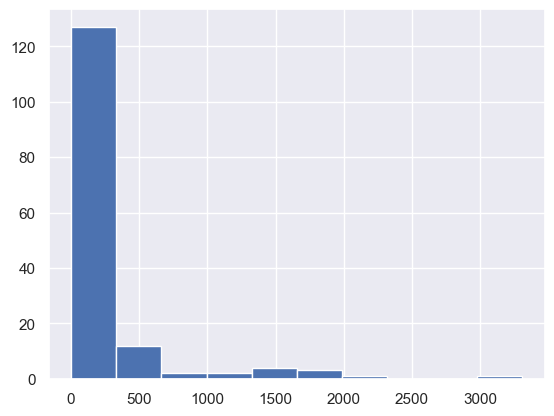

In [4]:
not_purchased = df_morethanone[df_morethanone.activity != "purchase"]
df_sims = not_purchased[not_purchased["game_name"] == "Dota 2"]
df_simshours = df_sims["hours_played_if_play"]
df_simshours.hist()

<AxesSubplot: >

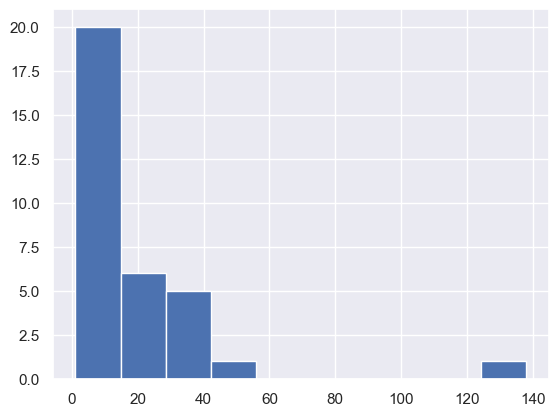

In [5]:
df_skyrim = not_purchased[not_purchased["game_name"] == "Unturned"]
df_skyhours = df_skyrim["hours_played_if_play"]
df_skyhours.hist()

**b)** Describe and compare the shapes of these histograms.
They are both skewed right. The second has an outlier between 120 and 140 hours of game play. 

**c)** Calculate and compare a measure of center for the number of hours played for each of these two games.  Explain why you chose your particular measure of center.

We chose this method since the median is most resistant to outliers.

In [6]:
df_simshours.median()

13.55

In [7]:
df_skyhours.median()

9.0

**d)** Calculate and compare a measure of spread for the number of hours played for each of these two games.  Explain why you chose your particular measure of spread.

I think it shows the variability of hours played per game. Althought it isn't resistant to outliers, it shows the dramatic differences in gameplay. 

In [8]:
range_sky = max(df_skyhours)-min(df_skyhours)
range_sky

136.9

In [9]:
range_sims = max(df_simshours)-min(df_simshours)
range_sims

3308.0

**e)** Calculate the cutoff points for observations to be considered an outlier for each of these two games.  Would you consider the set of cutoff points to be similar or different?

They are very different in the sense that the upper outliers are very far apart. The only similarity is that the lower bound outliers are not possible because they are negative, and there is no such thing as negative time. 

In [10]:
df_skyhours.describe()

count     33.000000
mean      17.672727
std       25.050527
min        1.100000
25%        3.700000
50%        9.000000
75%       21.000000
max      138.000000
Name: hours_played_if_play, dtype: float64

In [11]:
IQR = 21-3.7
IQR

17.3

In [12]:
q1 = 3.7
q2= 9
q3=21

In [13]:
UpperOutlier = q3 + ((1.5)*(IQR))
UpperOutlier

46.95

In [14]:
LowerOutlier = q1 - 1.5*(IQR)
LowerOutlier

-22.250000000000004

In [15]:
df_simshours.describe()

count     152.000000
mean      210.167105
std       480.014157
min         1.000000
25%         2.725000
50%        13.550000
75%       142.500000
max      3309.000000
Name: hours_played_if_play, dtype: float64

In [16]:
iqr = 139.775
Q1 = 2.725
Q3 = 142.5

In [17]:
upperoutlier = Q3+ 1.5*(iqr)
upperoutlier

352.1625

In [18]:
loweroutlier = Q1 - 1.5*(iqr)
loweroutlier

-206.93750000000003

### 3. Probability Calculation [4 pts]

Select one of the games from the two games you selected in Question 2 to further explore how popular that game is.  We will work to determine how popular that game is, based on how often the game is purchased and based on if the game has been played for our Steam users.

**a)** If a single game were to be randomly selected from the games (rows) that were purchased in this dataset, what is the probability that it is your selected game?

In [19]:
df_purchased = df[df.activity == "purchase"]
df_purchased


,user_id,game_name,activity,hours_played_if_play
0,308653033,Unturned,purchase,1.0
2,308653033,theHunter,purchase,1.0
3,144004384,Dota 2,purchase,1.0
5,54103616,Counter-Strike Global Offensive,purchase,1.0
7,54103616,Counter-Strike,purchase,1.0
...,...,...,...,...
7800,99096740,SimCity 4 Deluxe,purchase,1.0
7802,99096740,BioShock Infinite Burial at Sea - Episode 2,purchase,1.0
7803,99096740,The Elder Scrolls V Skyrim - Dawnguard,purchase,1.0
7804,99096740,The Elder Scrolls V Skyrim - Dragonborn,purchase,1.0


In [20]:
df_dota = df_purchased[df_purchased["game_name"] == "Dota 2"]
df_dota

,user_id,game_name,activity,hours_played_if_play
3,144004384,Dota 2,purchase,1.0
35,54103616,Dota 2,purchase,1.0
67,239397807,Dota 2,purchase,1.0
127,173857208,Dota 2,purchase,1.0
147,219446813,Dota 2,purchase,1.0
...,...,...,...,...
7673,218668551,Dota 2,purchase,1.0
7724,126690600,Dota 2,purchase,1.0
7750,147444403,Dota 2,purchase,1.0
7752,154531790,Dota 2,purchase,1.0


In [21]:
probability_dota = 197/4931
probability_dota

0.03995132833096735

**b)** Now, take a random sample of the user-game combinations (rows) of games that have been purchased of size 1000 with replacement.  Be sure to set the random_state beforehand, so that this sampling is replicable; you may choose any value for your random state.  Based on this random sample, what proportion of the games are your selected game.

In [22]:
df_random= df_purchased.sample(1000, replace=True, random_state=1234)
df_random

,user_id,game_name,activity,hours_played_if_play
4655,48798067,Eternal Silence,purchase,1.0
1215,60296891,Dungeonland,purchase,1.0
2199,174287424,GunZ 2 The Second Duel,purchase,1.0
5267,19696244,Half-Life Source,purchase,1.0
1099,81556495,Castle Crashers,purchase,1.0
...,...,...,...,...
3456,62078957,Team Fortress 2,purchase,1.0
4140,16084897,Ticket to Ride,purchase,1.0
1522,222259537,MicroVolts Surge,purchase,1.0
6968,174226719,PAYDAY 2,purchase,1.0


In [23]:
df_dota2= df_random[df_random["game_name"] == "Dota 2"]
df_dota2.count()

user_id                 36
game_name               36
activity                36
hours_played_if_play    36
dtype: int64

In [24]:
proportion_is_dota2 =36/1000
proportion_is_dota2

0.036

**c)** We'll continue examining the same game's popularity, now based on if that game is played.  If a single game were to be randomly selected from the user-game combination (rows) that have been played, what is the probability that it is your selected game?

In [25]:
df_played = df[df.activity == "play"]
df_played

,user_id,game_name,activity,hours_played_if_play
1,308653033,Unturned,play,0.6
4,144004384,Dota 2,play,22.0
6,54103616,Counter-Strike Global Offensive,play,1028.0
8,54103616,Counter-Strike,play,1008.0
10,54103616,Left 4 Dead,play,148.0
...,...,...,...,...
7793,99096740,Crysis,play,5.3
7795,99096740,Assassin's Creed II,play,2.7
7797,99096740,Hitman Blood Money,play,1.3
7799,99096740,The Binding of Isaac Rebirth,play,0.7


In [26]:
dota2 = df_played[df_played["game_name"] == "Dota 2"]
dota2

,user_id,game_name,activity,hours_played_if_play
4,144004384,Dota 2,play,22.0
36,54103616,Dota 2,play,3.1
68,239397807,Dota 2,play,0.4
128,173857208,Dota 2,play,0.6
148,219446813,Dota 2,play,210.0
...,...,...,...,...
7674,218668551,Dota 2,play,2.2
7725,126690600,Dota 2,play,0.2
7751,147444403,Dota 2,play,0.7
7753,154531790,Dota 2,play,0.1


In [27]:
prob_played_dota = 197/2875
prob_played_dota

0.06852173913043479

**d)** Finally, take a random sample of the user-game combinations (rows) of games that have been played of size 1000 with replacement.  Be sure to set the random_state beforehand, so that this sampling is replicable; you may choose any random state.  Based on this random sample, what proportion of the games are your selected game.

In [28]:
df_random_played= df_played.sample(1000, replace=True, random_state=1234)
df_random_played

,user_id,game_name,activity,hours_played_if_play
7779,99096740,Tomb Raider,play,16.8
1782,43684632,"Warhammer 40,000 Dawn of War II Retribution",play,1.5
3495,95780749,Orcs Must Die! 2,play,1.1
1664,43684632,Rust,play,22.0
5392,210018093,Dota 2,play,1.0
...,...,...,...,...
2170,174287424,Firefall,play,8.3
6128,57541240,Call of Duty Modern Warfare 2,play,15.3
1162,60296891,The Binding of Isaac,play,9.6
4414,48798067,Battlefield 2,play,16.3


In [29]:
dota2= df_random_played[df_random_played["game_name"] == "Dota 2"]
dota2.count()

user_id                 61
game_name               61
activity                61
hours_played_if_play    61
dtype: int64

In [30]:
proportion_is_dota_played = 61/1000
proportion_is_dota_played

0.061

**e)** Does the popularity of your game of interest differ based on whether it is played or purchased?  Explain your answer

There was 3.6% of the random sample of purchased games that were Dota 2, and 6.1% of the random played sample that was Dota 2. This shows that there is more interest in the game amongst people who have actually played it rather than those who have just purchased it. 